In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import tqdm
import seaborn as sns
from scipy.optimize import fsolve

# 2025

In [19]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
TEs=df_TEs.index.values
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [27]:
df_temp = pd.read_excel('../../Data/SLCP_temps.xlsx',header=[0])
df_temp.head()
years = df_temp['year'].to_numpy()
no_years = len(years)
scenarios = ['combined','co2_only']

In [23]:
# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df_temp[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df_temp[s].to_numpy()[t], T_lim, betas))

In [24]:
# ----------- SIMULATIONS ----------
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in (range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

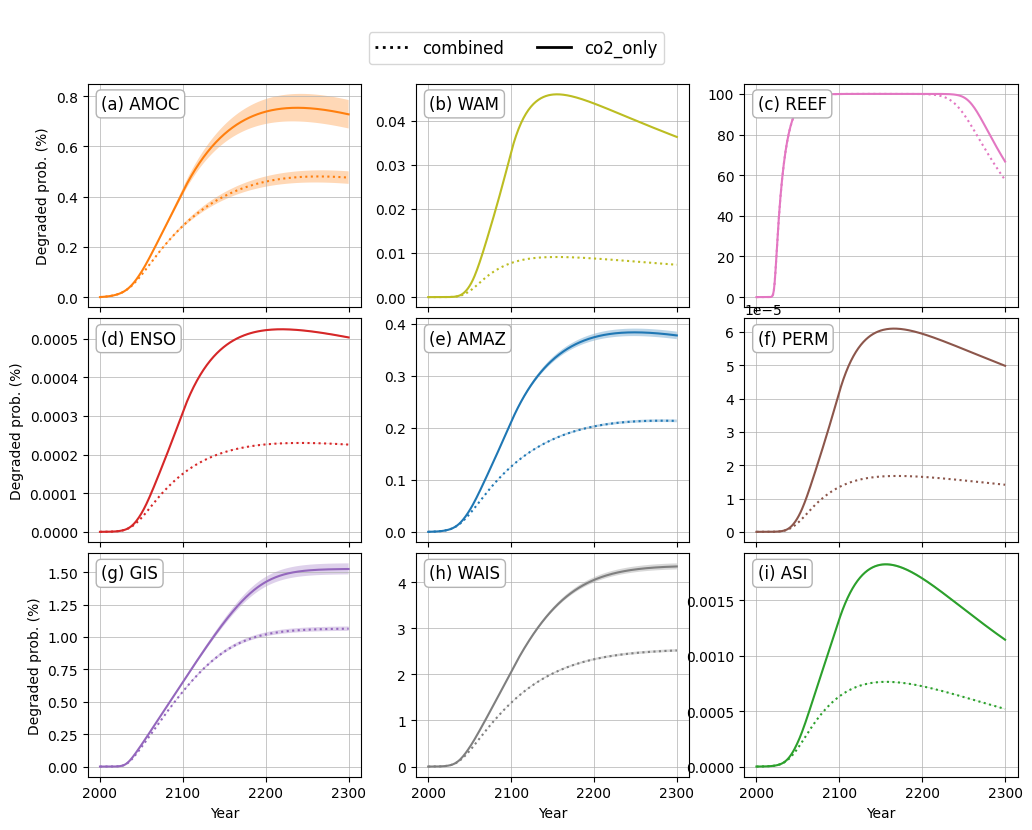

In [42]:
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
fig,axs = util.plot.TE_3x3_fig(TE_ordered=TE_ordered, subfig_lab_loc=[0.05,0.95],
                               ha='left',va='top',sharey=False)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':','-']
scen_labels = scenarios
TE_ind = {te:i for i,te in enumerate(TEs)}
ylims = [[-5,105]]*6+[[-.2,3.8], [-2,45], [-5,105]]
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j in range(len(scenarios)):
        util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], years, D[j,:,i,:]*100, color=colors[i],shade=[1],alpha=[0.3])
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    # axs[i_ax//3,i_ax%3].set_ylim(ylims[i_ax])
lines = [Line2D([0], [0], color=util.plot.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]
fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)

folder_out = '../../Figures/Methane/'
fig.savefig(folder_out+'individual_risk.png',format='png',dpi=300,bbox_inches='tight')

In [33]:
D.shape

(2, 500, 9, 301)

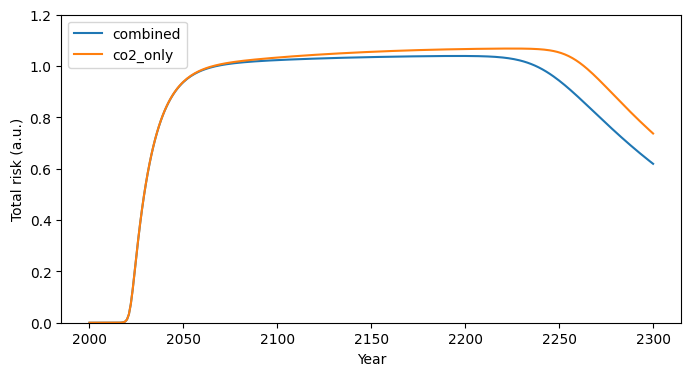

In [43]:
fig,ax = plt.subplots(figsize=(8,4))
for i,s in enumerate(scenarios):
    ax.plot(years,D[i,:,:,:].sum(axis=1).mean(axis=0),label=s)
ax.set_ylim([0,1.2])
ax.legend()
ax.set_ylabel('Total risk (a.u.)')
ax.set_xlabel('Year')
folder_out = '../../Figures/Methane/'
fig.savefig(folder_out+'total_risk.png',format='png',dpi=300,bbox_inches='tight')

In [60]:
D_ordered.shape

(9, 301)

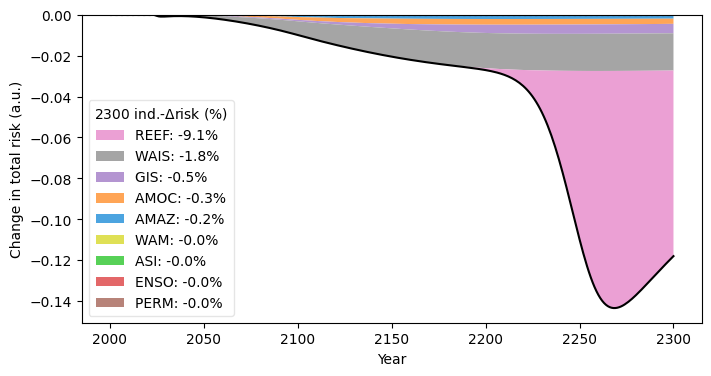

In [67]:
fig,ax = plt.subplots(figsize=(8,4))
ax.plot(years, (D[0,:,:,:]-D[1,:,:,:]).sum(axis=1).mean(axis=0),color='k')
ax.plot([2000,2300],[0,0],'k:')
order = (D[0,:,:,:]-D[1,:,:,:]).mean(axis=0)[:, -1].argsort()[::-1]
D_ordered = (D[0,:,:,:]-D[1,:,:,:]).mean(axis=0)[order]
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
ax.stackplot(years, D_ordered,zorder=1,
             colors = np.array([lighten_color(c,0.7)
                                for c in colors])[order],
             labels=np.array(TEs)[order])
ax.legend(loc='lower left',title='2300')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[::-1],
          labels=[l + ": {:.1f}%".format(D_ordered[i,-1]*100) for i,l in enumerate(labels)][::-1],
          # title=scenarios[scen_ind] + ': Final risks',
          ncols=1,loc='lower left',
          framealpha=0.5,title=r'2300 ind.-$\Delta$risk (%)')
ax.set_ylabel('Change in total risk (a.u.)')
ax.set_xlabel('Year')
folder_out = '../../Figures/Methane/'
fig.savefig(folder_out+'delta_risk_breakdown.png',format='png',dpi=300,bbox_inches='tight')

In [46]:
np.diff(D,axis=0).shape

(1, 500, 9, 301)

# 29-01-26

In [2]:
# Reading summary data from GTPR25
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
TEs=df_TEs.index.values
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy().reshape(1,9) # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy().reshape(1,9) # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [3]:
# Reading latest temperatures from IGSD ("PNAS - 3 Scenarios.xlsx")
xlsx = pd.ExcelFile('../../Data/PNAS - 3 Scenarios.xlsx')
tabs = xlsx.sheet_names
dfs = {tab: pd.read_excel(xlsx, header=[0], sheet_name=tab) for tab in tabs}

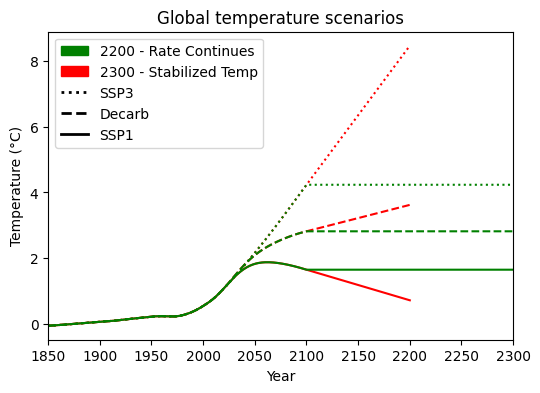

In [56]:
linestyles = [':','--','-']
labels = ['SSP3', 'Decarb', 'SSP1']
colors = ['r','g']

fig,ax=plt.subplots(figsize=(6,4))

for i,tab in enumerate(tabs[1:]):
    for j,s in enumerate(dfs[tab].columns.values[1:]):
        ax.plot(range(1850,1850+len(dfs[tab])), dfs[tab][s].to_numpy(),ls=linestyles[j],color=colors[i])

ax.set_xlim(1850,2300)
ax.set_ylabel("Temperature (°C)")
ax.set_xlabel("Year")
ax.set_title("Global temperature scenarios")

# legend_elements = [Line2D([0], [0], color='k', lw=2, ls=linestyles[i], label=labels[i]) for i in range(3)] 
legend_elements = [Patch(facecolor='g', edgecolor='g',
                         label=tabs[1]),
                   Patch(facecolor='r', edgecolor='r',
                         label=tabs[2])] + [Line2D([0], [0], color='k', lw=2, ls=linestyles[i], label=labels[i]) for i in range(3)] 
ax.legend(handles=legend_elements, loc='upper left',ncols=1)

folder_out = '../../Figures/Methane/3_scenarios/'
fig.savefig(folder_out+'temperatures.png',bbox_inches='tight')

In [4]:
# Modifying collapse probabilities for each year according to each scenario
p_c = {tab: np.ones((3, len(dfs[tab]), len(df_TEs)))*q_c for tab in tabs}
p_r = {tab: np.ones((3, len(dfs[tab]), len(df_TEs)))*q_r for tab in tabs}

for tab in tabs:
    df = dfs[tab]
    for i,s in enumerate(dfs[tab].columns.values[1:]):
        sigma = temp_response(dfs[tab][s].to_numpy().reshape(len(df),1), T_lim.reshape(1,9), betas.reshape(1,9))
        p_c[tab][i,:,:] *= sigma
        p_r[tab][i,:,:] *= (1-sigma)

In [5]:
# ----------- SIMULATIONS ----------
D = {tab: np.zeros((3, len_sample, len(df_TEs), len(dfs[tab]) )) 
     for tab in tabs}

# iterating over tabs in the excel sheet
for tab in tabs: 
    # iterating over interaction matrices
    for r in (range(len_sample)):
        # iterating over scenarios within each tab
        for j in range(3):
            # iterating over years
            for t in range(1,len(dfs[tab])):
                D[tab][j,r,:,t] = environmental_update(D[tab][j,r,:,t-1],
                                                       A[r],
                                                       pc=p_c[tab][j,t,:],pr=p_r[tab][j,t,:])

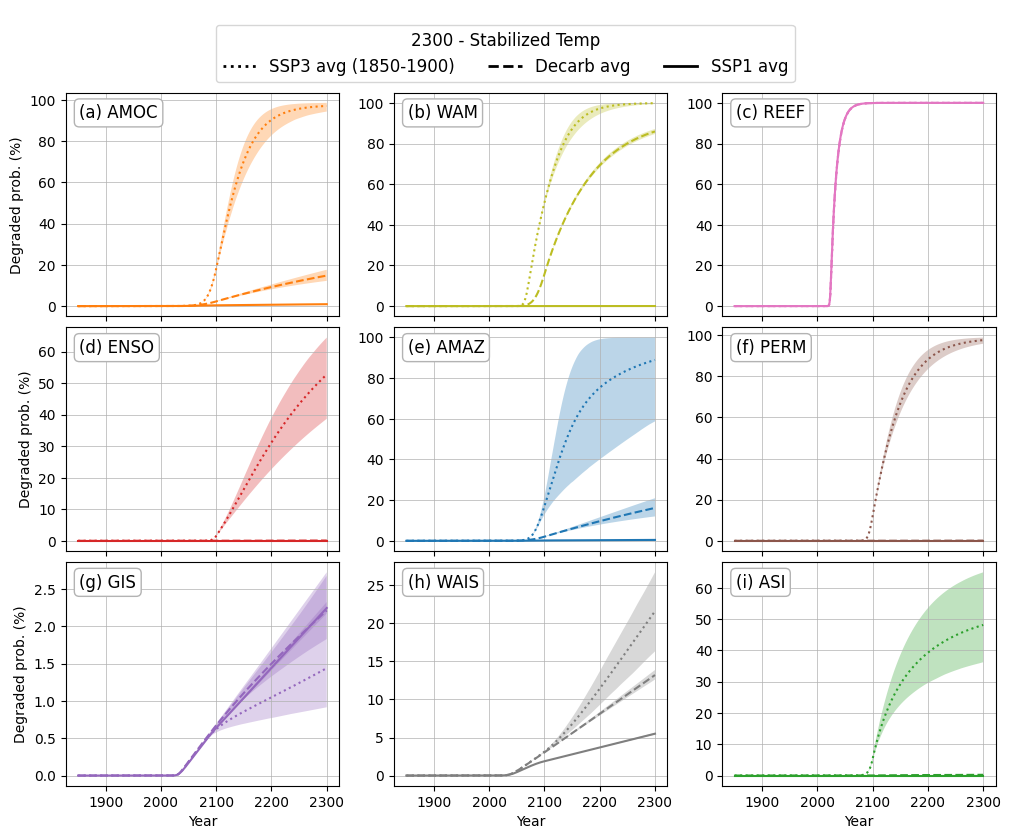

In [60]:
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
fig,axs = util.plot.TE_3x3_fig(TE_ordered=TE_ordered, subfig_lab_loc=[0.05,0.95],
                               ha='left',va='top',sharey=False)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':','--','-']

TE_ind = {te:i for i,te in enumerate(TEs)}
# ylims = [[-5,105]]*6+[[-.2,3.8], [-2,45], [-5,105]]
ylims=[[0,10]]*9

tab = tabs[2]
scen_labels = dfs[tab].columns.values[1:]
years = dfs[tab]['Year'].to_numpy()

for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j in range(len(scen_labels)):
        util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], years, D[tab][j,:,i,:]*100, color=colors[i],shade=[1],alpha=[0.3])
        axs[i_ax//3,i_ax%3].plot(years,D[tab][j,:,i,:].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    # axs[i_ax//3,i_ax%3].set_ylim(ylims[i_ax])
lines = [Line2D([0], [0], color=util.plot.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scen_labels))]
fig.legend(handles=lines,ncols=len(scen_labels),loc='upper center',
           prop={'size':12},borderaxespad=1.5,title=tab,title_fontsize=12)

# axs[0,0].set_xlim(2020,2120)
folder_out = '../../Figures/Methane/3_scenarios/'
fig.savefig(folder_out+tab+'_individual_risk.png',format='png',bbox_inches='tight')

In [17]:
ylims = [[0,100]]*9
print(ylims)

[[0, 100], [0, 100], [0, 100], [0, 100], [0, 100], [0, 100], [0, 100], [0, 100], [0, 100]]


In [7]:
df_TEs

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,1.5,3.50,6.0,3.453377,0.20,Updated lower threshold from 2C (GTPR23) to 1....
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.00,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,3.0,4.50,6.0,4.604503,0.60,Updated estimates entirely from AM22 values in...
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.50,6.0,4.604503,0.00,NaN
GIS,Greenland ice sheet,10000,100000,0.8,1.50,3.4,9.866793,0.13,Updated upper estimate from 3C (GTPR23) to 3.4...
PERM,Boreal permafrost collapse,50,500,3.0,4.00,6.0,6.906755,0.30,NaN
REEF,Low-latitude coral reefs,10,100,1.0,1.20,1.5,34.533774,0.00,Upper estimate reduced from 2C (AM22) to 1.5C ...
WAIS,West Antarctic ice sheet,2000,20000,0.5,1.75,3.0,5.525404,0.05,NaN
WAM,Sahel and West African monsoon,50,500,2.0,2.80,3.5,8.633443,0.00,NaN


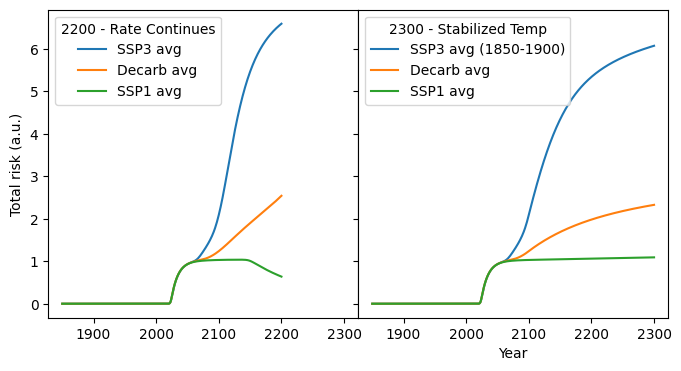

In [72]:
fig,axs = plt.subplots(figsize=(8,4),ncols=2,sharey=True,sharex=True)
fig.subplots_adjust(wspace=0)
for i_ax in range(2):
    tab = tabs[i_ax+1]
    for i,s in enumerate(dfs[tab].columns.values[1:]):
        axs[i_ax].plot(dfs[tab]['Year'].to_numpy(),D[tab][i,:,:,:].sum(axis=1).mean(axis=0),label=s)
    # ax.set_ylim([0,1.2])
    axs[i_ax].legend(title=tab,title_fontsize=10)
axs[0].set_ylabel('Total risk (a.u.)')
axs[1].set_xlabel('Year')
folder_out = '../../Figures/Methane/'
fig.savefig(folder_out+'3_scenarios_total_risk.png',format='png',bbox_inches='tight')

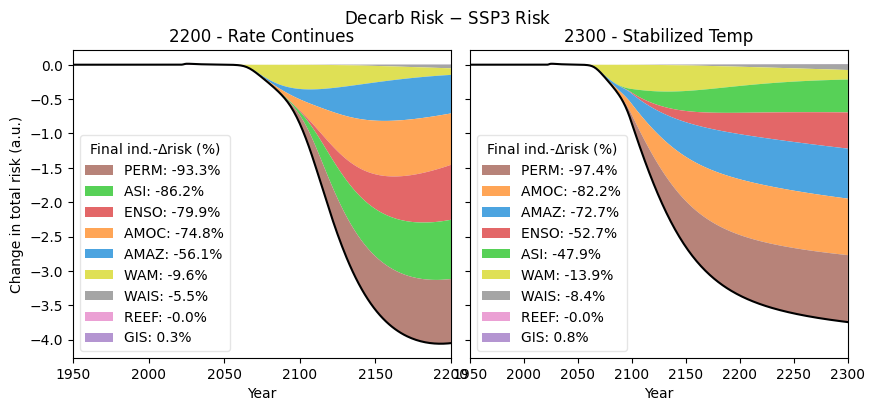

In [73]:
fig,axs = plt.subplots(figsize=(10,4),ncols=2,sharex=False,sharey=True)
fig.subplots_adjust(wspace=0.05)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

scen_minus_scen = [1,0]
scen_labels = ['SSP3', 'Decarb', 'SSP1']

for i_ax,ax in enumerate(axs):
    tab=tabs[i_ax+1]
    years=dfs[tab]['Year'].to_numpy()
    deltaD = D[tab][scen_minus_scen[0],:,:,:]- D[tab][scen_minus_scen[1],:,:,:]
    ax.plot(years, deltaD.sum(axis=1).mean(axis=0),color='k')
    order = deltaD.mean(axis=0)[:, -1].argsort()[::-1]
    D_ordered = deltaD.mean(axis=0)[order]
    
    
    ax.stackplot(years, D_ordered,zorder=1,
                 colors = np.array([lighten_color(c,0.7)
                                    for c in colors])[order],
                 labels=np.array(TEs)[order])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles=handles[::-1],
              labels=[l + ": {:.1f}%".format(D_ordered[i,-1]*100) for i,l in enumerate(labels)][::-1],
              # title=scenarios[scen_ind] + ': Final risks',
              ncols=1,loc='lower left',
              framealpha=0.5,title=r'Final ind.-$\Delta$risk (%)')
    ax.set_xlim(1950,years[-1])
    ax.set_xlabel('Year')
    ax.set_title(tab)
axs[0].set_ylabel('Change in total risk (a.u.)')

fig.suptitle("%s Risk $-$ %s Risk"%(scen_labels[scen_minus_scen[0]], scen_labels[scen_minus_scen[1]]))

folder_out = '../../Figures/Methane/3_scenarios/'
# fig.savefig(folder_out+'change_in_risk_%s_vs_%s.png'%(scen_labels[scen_minus_scen[0]], 
#                                                       scen_labels[scen_minus_scen[1]]),
#             format='png',bbox_inches='tight')